In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score




train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print(train.isnull().sum())
print("-----------------------------------")
print(test.isnull().sum())
print(test.info())
print(train.shape)
test.shape

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
-----------------------------------
PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    object 
 3   Sex          418 non-null    object 
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       

(418, 11)

In [104]:
train["Survived"].value_counts(normalize=True) * 100


Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

In [105]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [106]:
train.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [107]:
pd.crosstab(train["Sex"], train["Survived"])

Survived,0,1
Sex,,
female,81,233
male,468,109


In [108]:
train.groupby("Parch")["Survived"].mean()*100

Parch
0      34.268833
1      55.084746
2      50.000000
3      60.000000
4       0.000000
5      20.000000
6       0.000000
58    100.000000
Name: Survived, dtype: float64

#Sex and Pclass are strongly associated with survival.

In [109]:
train.groupby(["Pclass", "Sex"])["Survived"].mean() 

Pclass  Sex   
1       female    0.968085
        male      0.368852
2       female    0.921053
        male      0.157407
3       female    0.500000
        male      0.135447
Name: Survived, dtype: float64

# Survival distribution

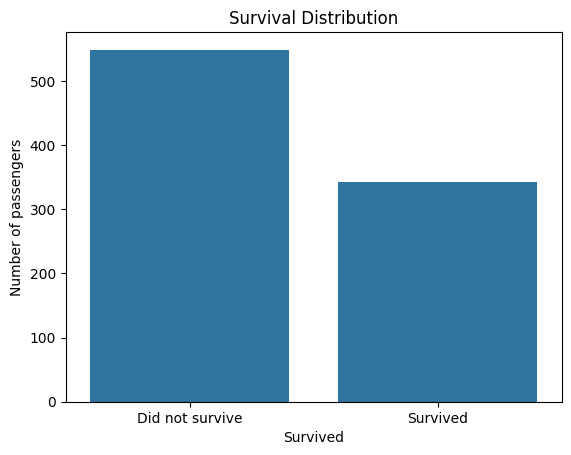

In [110]:
sns.countplot(data=train, x="Survived")
plt.title("Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Number of passengers")
plt.xticks([0, 1], ["Did not survive", "Survived"])
plt.show()

## Survival Rate by Sex

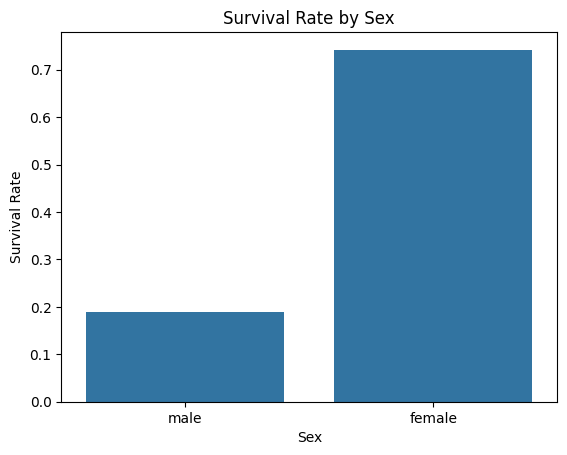

In [111]:
sns.barplot(data=train, x="Sex", y="Survived", errorbar=None)

plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")

plt.show()

## Survival Rate by Passenger Class

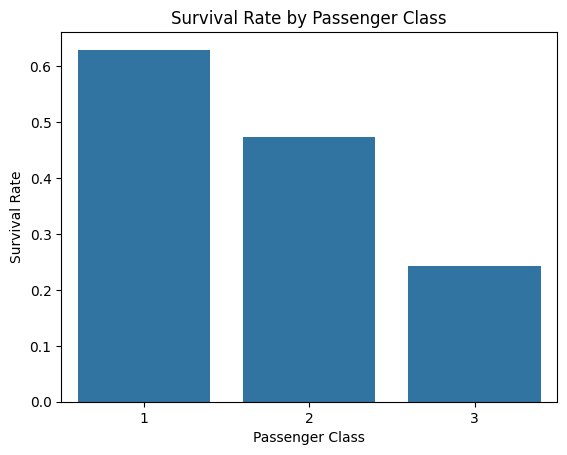

In [112]:
sns.barplot(data=train, x="Pclass", y="Survived", errorbar=None)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

## Survival Rate by Passenger Class and Sex

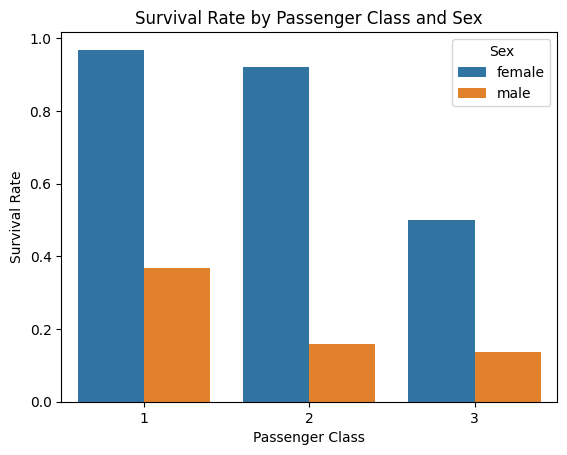

In [113]:
sns.barplot(
    data=train,
    x="Pclass",
    y="Survived",
    hue="Sex",
    errorbar=None
)

plt.title("Survival Rate by Passenger Class and Sex")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

## Age Distribution by Survival

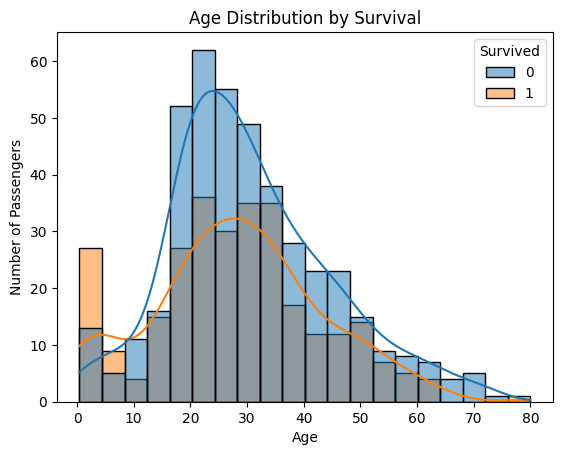

In [114]:
sns.histplot(
    data=train,
    x="Age",
    hue="Survived",
    kde=True
)

plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

## Average Fare by Survival

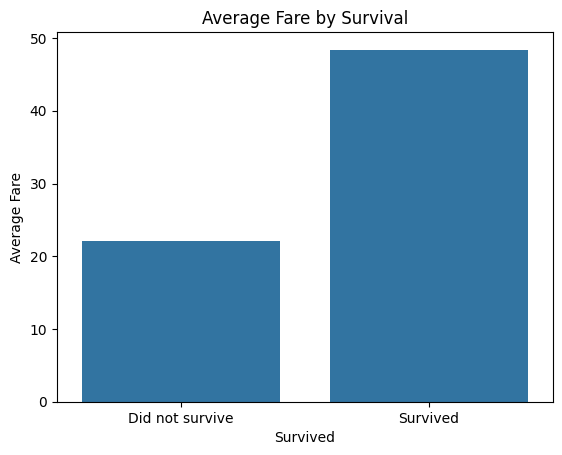

In [115]:
sns.barplot(data=train, x="Survived", y="Fare", errorbar=None)

plt.title("Average Fare by Survival")
plt.xlabel("Survived")
plt.ylabel("Average Fare")
plt.xticks([0, 1], ["Did not survive", "Survived"])

plt.show()

## Survival Rate by Number of Siblings or Spouses

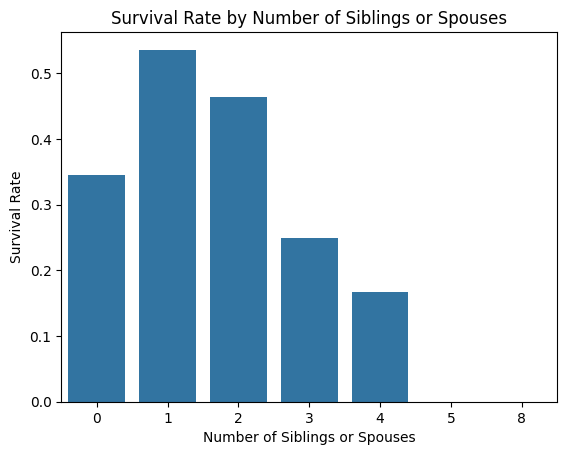

In [116]:
sns.barplot(data=train, x="SibSp", y="Survived", errorbar=None)

plt.title("Survival Rate by Number of Siblings or Spouses")
plt.xlabel("Number of Siblings or Spouses")
plt.ylabel("Survival Rate")

plt.show()

## Survival Rate by Family Size

In [117]:
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1
test["FamilySize"] = test["SibSp"] + test["Parch"] + 1

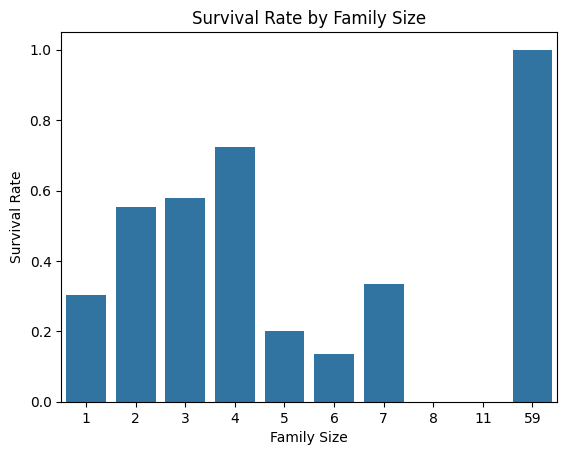

In [118]:
sns.barplot(data=train, x="FamilySize", y="Survived", errorbar=None)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate")

plt.show()

## Survival Rate by Port of Embarkation

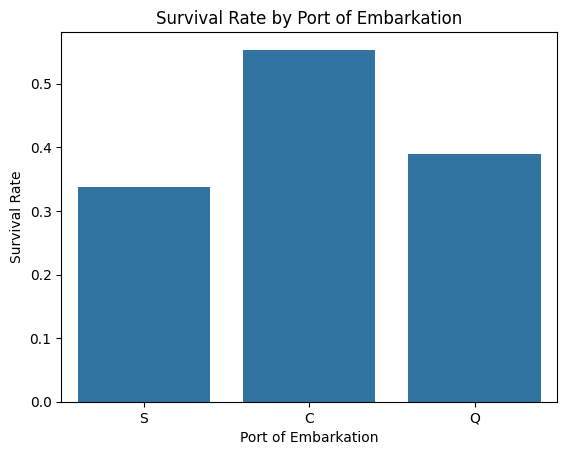

In [119]:
sns.barplot(data=train, x="Embarked", y="Survived", errorbar=None)

plt.title("Survival Rate by Port of Embarkation")
plt.xlabel("Port of Embarkation")
plt.ylabel("Survival Rate")

plt.show()

# Data Cleaning

In [120]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
FamilySize       0
dtype: int64

In [121]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
 12  FamilySize   891 non-null    int64  
dtypes: float64(2), int64(6), object(5)
memory usage: 90.6+ KB


In [122]:
train["CabinKnown"] = train["Cabin"].notna().astype(int)
test["CabinKnown"] = test["Cabin"].notna().astype(int)

In [123]:
train["CabinKnown"].value_counts()

CabinKnown
0    687
1    204
Name: count, dtype: int64

In [124]:
test["CabinKnown"].value_counts()

CabinKnown
0    327
1     91
Name: count, dtype: int64

In [125]:
train.drop("Cabin",axis=1,inplace=True)
test.drop("Cabin",axis=1,inplace=True)

In [126]:
age_median = train["Age"].median()
train["Age"] = train["Age"].fillna(age_median)
test["Age"] = test["Age"].fillna(age_median)

In [127]:
embarked_mode = train["Embarked"].mode()[0]

print(embarked_mode)

S


In [128]:
train["Embarked"] = train["Embarked"].fillna(embarked_mode)
test["Embarked"] = train["Embarked"].fillna(embarked_mode)


In [129]:
fare_median = train["Fare"].median()
test["Fare"] = test["Fare"].fillna(fare_median)



In [130]:
print("TRAIN")
print(train.isnull().sum())
print("\nTEST")
print(test.isnull().sum())

TRAIN
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
FamilySize     0
CabinKnown     0
dtype: int64

TEST
PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
FamilySize     0
CabinKnown     0
dtype: int64


## Feature Engineering


In [131]:
train["IsAlone"] = (train["FamilySize"] == 1).astype(int)
test["IsAlone"] = (test["FamilySize"] == 1).astype(int)


In [132]:
train.groupby("IsAlone")["Survived"].mean()

IsAlone
0    0.507042
1    0.302239
Name: Survived, dtype: float64

In [133]:

print(train["Sex"].value_counts())
print(train["Sex"].unique())
train["Sex"].head


Sex
male      577
female    314
Name: count, dtype: int64
['male' 'female']


<bound method NDFrame.head of 0        male
1      female
2      female
3      female
4        male
        ...  
886      male
887    female
888    female
889      male
890      male
Name: Sex, Length: 891, dtype: object>

In [134]:
train["Sex"] = train["Sex"].map({
    "male": 0,
    "female": 1
})

test["Sex"] = test["Sex"].map({
    "male": 0,
    "female": 1
})
print(train["Sex"].value_counts())
print(test["Sex"].value_counts())

Sex
0    577
1    314
Name: count, dtype: int64
Sex
0    266
1    152
Name: count, dtype: int64


In [135]:
train["Sex_Pclass"] = train["Sex"] * train["Pclass"] 
test["Sex-Pclass"] = test["Sex"] * train["Pclass"]

In [136]:
train["Embarked"] = train["Embarked"].map({
    "S": 0,
    "C": 1,
    "Q": 2
})

test["Embarked"] = test["Embarked"].map({
    "S": 0,
    "C": 1,
    "Q": 2
})

In [137]:
print(train["Embarked"].value_counts())
print(test["Embarked"].value_counts())

Embarked
0    646
1    168
2     77
Name: count, dtype: int64
Embarked
0    297
1     80
2     41
Name: count, dtype: int64


In [138]:
print(train["Embarked"].isnull().sum())
print(test["Embarked"].isnull().sum())


0
0


## training

In [139]:
X = train.drop("Survived", axis=1)
y = train["Survived"]

X = X.drop(["PassengerId", "Name", "Ticket"], axis=1)

X_test = test.drop(["PassengerId", "Name", "Ticket"], axis=1)
print(X_test)

     Pclass  Sex   Age  SibSp  Parch      Fare  Embarked  FamilySize  \
0         3    0  34.5      0      0    7.8292         0           1   
1         3    1  47.0      1      0    7.0000         1           2   
2         2    0  62.0      0      0    9.6875         0           1   
3         3    0  27.0      0      0    8.6625         0           1   
4         3    1  22.0      1      1   12.2875         0           3   
..      ...  ...   ...    ...    ...       ...       ...         ...   
413       3    0  28.0      0      0    8.0500         0           1   
414       1    1  39.0      0      0  108.9000         0           1   
415       3    0  38.5      0      0    7.2500         0           1   
416       3    0  28.0      0      0    8.0500         0           1   
417       3    0  28.0      1      1   22.3583         0           3   

     CabinKnown  IsAlone  Sex-Pclass  
0             0        1         0.0  
1             0        0         1.0  
2             0   

### X -> al feuture sauf Survived
### y -> Survived


In [140]:
print(X.columns)
print(X.shape)

print(X_test.columns)
print(X_test.shape)

Index(['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked',
       'FamilySize', 'CabinKnown', 'IsAlone', 'Sex_Pclass'],
      dtype='object')
(891, 11)
Index(['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked',
       'FamilySize', 'CabinKnown', 'IsAlone', 'Sex-Pclass'],
      dtype='object')
(418, 11)


In [141]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)



### X_train -> 80% used for trainaing
### y_trai ->  80% used for validit trainig
### X_val ->   20% used for testing
### y_val -> 20% used for validiot testing  

In [142]:
model = LogisticRegression(max_iter=1000)

In [143]:
model.fit(X_train, y_train)
#hsdgsgdjfj

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [153]:
y_pred = model.predict(X_val)
test_predictions = model.predict(test)

print(y_pred)

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- Name
- PassengerId
- Sex-Pclass
- Ticket
Feature names seen at fit time, yet now missing:
- Sex_Pclass


In [145]:

accuracy = accuracy_score(y_val, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8268156424581006


In [146]:
submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test
})

submission.to_csv("submission.csv", index=False)

ValueError: 2

In [ ]:

cm = confusion_matrix(y_val, y_pred)

print(cm)

[[102   8]
 [ 23  46]]


In [ ]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("CV scores:", cv_scores)
print("Mean accuracy:", cv_scores.mean())
print("Std:", cv_scores.std())

CV scores: [0.80446927 0.78089888 0.79775281 0.79213483 0.82022472]
Mean accuracy: 0.7990961019396147
Std: 0.013089630844262123


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

scaled_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000))
])

scaled_model.fit(X_train, y_train)

scaled_pred = scaled_model.predict(X_val)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_val, scaled_pred))
print(classification_report(y_val, scaled_pred))

Accuracy: 0.8156424581005587
              precision    recall  f1-score   support

           0       0.80      0.94      0.86       110
           1       0.86      0.62      0.72        69

    accuracy                           0.82       179
   macro avg       0.83      0.78      0.79       179
weighted avg       0.82      0.82      0.81       179



In [ ]:
scaled_cv_scores = cross_val_score(
    scaled_model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("CV scores:", scaled_cv_scores)
print("Mean accuracy:", scaled_cv_scores.mean())
print("Std:", scaled_cv_scores.std())

CV scores: [0.81005587 0.78089888 0.82022472 0.78651685 0.83146067]
Mean accuracy: 0.8058313979034587
Std: 0.019372949509726595


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train, y_train)

,estimator,LogisticRegre...max_iter=1000)
,param_grid,"{'C': [0.001, 0.01, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [ ]:
print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", grid_search.best_score_)

Best parameters: {'C': 100}
Best CV accuracy: 0.818881118881119


In [ ]:
best_model = grid_search.best_estimator_

best_pred = best_model.predict(X_val)

print("Validation accuracy:", accuracy_score(y_val, best_pred))
print(classification_report(y_val, best_pred))

Validation accuracy: 0.7988826815642458
              precision    recall  f1-score   support

           0       0.78      0.93      0.85       110
           1       0.84      0.59      0.69        69

    accuracy                           0.80       179
   macro avg       0.81      0.76      0.77       179
weighted avg       0.80      0.80      0.79       179



In [ ]:

final_model = LogisticRegression(
    C=grid_search.best_params_["C"],
    max_iter=1000
)

final_model.fit(X, y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,100
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [ ]:
print(final_model)

LogisticRegression(C=100, max_iter=1000)


In [ ]:

print(pd.Series(test_predictions).value_counts())

NameError: name 'test_predictions' is not defined

ValueError: array length 179 does not match index length 418

In [ ]:
print(submission.shape)
print(submission.head())

In [ ]:
import os

print(os.path.exists("submission.csv"))
##  hjzgedjzagd djhdjsu
